In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.random.seed(0)
X, y = make_moons(n_samples=1200, noise=0.25, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)
print("Xtr:", Xtr.shape, "Xte:", Xte.shape)

Xtr: (840, 2) Xte: (360, 2)


In [2]:
def relu(x):
    return np.maximum(0, x)

def relu_grad(x):
    return (x > 0).astype(float)

class Layer:
    """Couche dense (Linear) avec forward/backward manuels (descente de gradient)."""
    def __init__(self, din, dout, seed):
        rng = np.random.RandomState(seed)
        self.W = rng.randn(din, dout) * np.sqrt(2.0 / din)   # init de type He
        self.b = np.zeros(dout)

    def fwd(self, x):
        self.x = x
        self.z = x @ self.W + self.b
        return self.z

    def bwd(self, dz, lr):
        dW = self.x.T @ dz / dz.shape[0]
        db = dz.mean(axis=0)
        dx = dz @ self.W.T
        self.W -= lr * dW
        self.b -= lr * db
        return dx

print("Classe Layer définie.")

Classe Layer définie.


In [3]:
class Net:
    """
    Empile `n_blocks` blocs [Linear -> ReLU -> Linear].
    - residual=False : réseau "plain" tel que défini dans le papier (Fig. 3, milieu)
    - residual=True  : ajoute le raccourci identité F(x) + x avant la ReLU finale
                        du bloc (Eqn. 1 et Fig. 2 du papier), comme le bloc
                        résiduel de la Fig. 3 (droite).
    """
    def __init__(self, n_blocks, width, din, nclass, residual, seed=0):
        self.residual = residual
        self.inp = Layer(din, width, seed)
        self.blocks = [(Layer(width, width, seed + 10 * i + 1),
                         Layer(width, width, seed + 10 * i + 2))
                        for i in range(n_blocks)]
        self.out = Layer(width, nclass, seed + 999)

    def forward(self, x):
        h = relu(self.inp.fwd(x))
        self.acts = [h]
        for (l1, l2) in self.blocks:
            a1 = relu(l1.fwd(h))
            a2 = l2.fwd(a1)
            if self.residual:
                a2 = a2 + h              # shortcut identité : F(x) + x
            h = relu(a2)
            self.acts.append(h)
        return self.out.fwd(h)

    def backward(self, dlogits, lr):
        dh = self.out.bwd(dlogits, lr)
        idx = len(self.blocks) - 1
        for (l1, l2) in reversed(self.blocks):
            da2 = dh * relu_grad(l2.z + (self.acts[idx] if self.residual else 0))
            dshort = da2 if self.residual else 0
            dl2in = l2.bwd(da2, lr)
            da1 = dl2in * relu_grad(l1.z)
            dl1in = l1.bwd(da1, lr)
            dh = dl1in + dshort          # le gradient du shortcut s'ajoute (dérivée de x dans F(x)+x)
            idx -= 1
        dh = dh * relu_grad(self.inp.z)
        self.inp.bwd(dh, lr)

print("Classe Net (plain / résiduelle) définie.")

Classe Net (plain / résiduelle) définie.


In [4]:
def softmax_loss(logits, y):
    logits = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(logits)
    probs = exp / exp.sum(axis=1, keepdims=True)
    n = y.shape[0]
    loss = -np.log(probs[np.arange(n), y] + 1e-9).mean()
    dlogits = probs.copy()
    dlogits[np.arange(n), y] -= 1
    dlogits /= n
    return loss, dlogits

def accuracy(logits, y):
    return (logits.argmax(axis=1) == y).mean()

def train(net, Xtr, ytr, Xte, yte, epochs=120, lr=0.05, bs=64, seed=0):
    rng = np.random.RandomState(seed)
    n = Xtr.shape[0]
    hist = {"train_loss": [], "train_err": [], "test_err": []}
    for ep in range(epochs):
        perm = rng.permutation(n)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            logits = net.forward(Xtr[idx])
            loss, dlogits = softmax_loss(logits, ytr[idx])
            net.backward(dlogits, lr)
        logits_tr = net.forward(Xtr)
        loss_tr, _ = softmax_loss(logits_tr, ytr)
        hist["train_loss"].append(loss_tr)
        hist["train_err"].append(1 - accuracy(logits_tr, ytr))
        hist["test_err"].append(1 - accuracy(net.forward(Xte), yte))
    return hist

print("Fonctions de perte / entraînement définies.")

Fonctions de perte / entraînement définies.


In [5]:
# Quatre configurations : peu profond vs profond, plain vs résiduel.
# Le nombre de blocs a été volontairement choisi (10 blocs) pour faire apparaître
# le "problème de dégradation" décrit dans le papier (Fig. 1) : au-delà d'une
# certaine profondeur, le réseau "plain" devient nettement plus difficile à
# optimiser avec une simple SGD (pas de Batch Normalization ici, afin de
# rendre le phénomène plus visible à cette petite échelle).
configs = [
    ("Plain - 3 blocs (peu profond)",   3, False, "#1f77b4"),
    ("Plain - 10 blocs (profond)",     10, False, "#d62728"),
    ("ResNet - 3 blocs (peu profond)",  3, True,  "#2ca02c"),
    ("ResNet - 10 blocs (profond)",    10, True,  "#9467bd"),
]

results = {}
print(f"{'Modele':32s} {'Erreur train (%)':>18s} {'Erreur test (%)':>18s}")
for name, nb, res, color in configs:
    net = Net(n_blocks=nb, width=32, din=2, nclass=2, residual=res, seed=5)
    hist = train(net, Xtr, ytr, Xte, yte, epochs=120, lr=0.05, bs=64, seed=1)
    results[name] = (hist, color)
    print(f"{name:32s} {hist['train_err'][-1]*100:18.2f} {hist['test_err'][-1]*100:18.2f}")

Modele                             Erreur train (%)    Erreur test (%)
Plain - 3 blocs (peu profond)                 11.31              12.22
Plain - 10 blocs (profond)                    36.31              37.22
ResNet - 3 blocs (peu profond)                10.71              10.56
ResNet - 10 blocs (profond)                    9.05              11.11


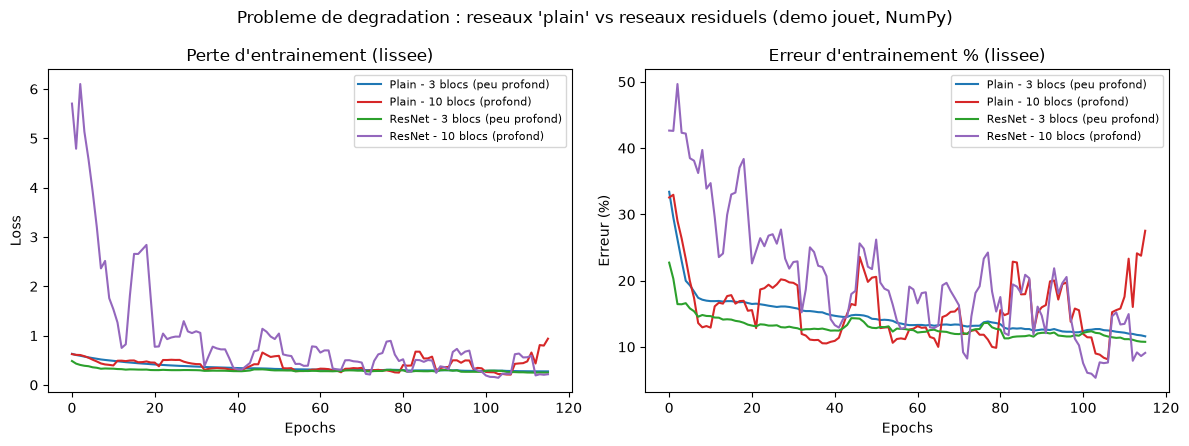

In [6]:
def smooth(v, w=5):
    v = np.array(v)
    if len(v) < w:
        return v
    return np.convolve(v, np.ones(w) / w, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (hist, color) in results.items():
    axes[0].plot(smooth(hist["train_loss"]), label=name, color=color)
    axes[1].plot(smooth(np.array(hist["train_err"]) * 100), label=name, color=color)
axes[0].set_title("Perte d'entrainement (lissee)")
axes[0].set_xlabel("Epochs"); axes[0].set_ylabel("Loss")
axes[1].set_title("Erreur d'entrainement % (lissee)")
axes[1].set_xlabel("Epochs"); axes[1].set_ylabel("Erreur (%)")
for ax in axes:
    ax.legend(fontsize=8)
plt.suptitle("Probleme de degradation : reseaux 'plain' vs reseaux residuels (demo jouet, NumPy)")
plt.tight_layout()
plt.show()

In [7]:
p3 = results["Plain - 3 blocs (peu profond)"][0]["train_err"][-1] * 100
pD = results["Plain - 10 blocs (profond)"][0]["train_err"][-1] * 100
r3 = results["ResNet - 3 blocs (peu profond)"][0]["train_err"][-1] * 100
rD = results["ResNet - 10 blocs (profond)"][0]["train_err"][-1] * 100

print("Resume :")
print(f" - En passant de 3 a 10 blocs SANS raccourci residuel, l'erreur d'entrainement")
print(f"   passe de {p3:.1f}% a {pD:.1f}% : le reseau plus profond est plus difficile a")
print(f"   optimiser (degradation), alors qu'il a strictement plus de capacite.")
print(f" - Avec des raccourcis residuels (shortcuts identite), l'erreur passe de")
print(f"   {r3:.1f}% a {rD:.1f}% : le reseau profond egale ou surpasse le reseau peu profond.")
print()
print("Cela illustre, a tres petite echelle et sans Batch Normalization, le")
print("phenomene central du papier de He et al. (2015) : les connexions")
print("residuelles facilitent l'optimisation des reseaux profonds, la ou les")
print("reseaux 'plain' equivalents se degradent.")

Resume :
 - En passant de 3 a 10 blocs SANS raccourci residuel, l'erreur d'entrainement
   passe de 11.3% a 36.3% : le reseau plus profond est plus difficile a
   optimiser (degradation), alors qu'il a strictement plus de capacite.
 - Avec des raccourcis residuels (shortcuts identite), l'erreur passe de
   10.7% a 9.0% : le reseau profond egale ou surpasse le reseau peu profond.

Cela illustre, a tres petite echelle et sans Batch Normalization, le
phenomene central du papier de He et al. (2015) : les connexions
residuelles facilitent l'optimisation des reseaux profonds, la ou les
reseaux 'plain' equivalents se degradent.


## Conclusion

Ce mini-modèle, entraîné en quelques secondes sur CPU, retrouve qualitativement
le résultat central du papier :

- un réseau **plain** plus profond peut être **plus dur à optimiser** qu'un
  réseau moins profond (problème de dégradation, Fig. 1 et Fig. 4 du papier) ;
- l'ajout de **connexions résiduelles** (identité, `F(x) + x`) restaure — voire
  améliore — les performances du réseau profond, sans paramètre supplémentaire
  (Eqn. 1, Fig. 2 et Fig. 3 du papier).

Pour une reproduction fidèle des résultats ImageNet/CIFAR-10 du papier
(ResNet-18/34/50/101/152, top-5 3.57 % sur ImageNet), il faudrait un
environnement avec GPU et un framework de deep learning (PyTorch/TensorFlow),
non disponibles dans ce conteneur d'exécution hors-ligne.